# Marriott 2020 Category Changes — Exploratory Analysis

**Assignment 1, Part 1.** The dataset is every Marriott hotel whose loyalty category changed in 2020 (the changes took effect **4 March 2020**). One row per hotel.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

# colourblind-safe categorical hue (single series -> one colour)
BLUE = "#2a78d6"

df = pd.read_csv("marriott-category-changes-2020.csv")
df.head()

,hotel,brand,destination,current_category,current_price,new_category,new_price
0,Aberdeen Marriott Hotel,Marriott,United Kingdom,3,17500,2,12500
1,AC Hotel Aitana,AC Hotels by Marriott,Spain,3,17500,4,25000
2,AC Hotel Alcala de Henares,AC Hotels by Marriott,Spain,1,7500,2,12500
3,AC Hotel Almeria,AC Hotels by Marriott,Spain,1,7500,2,12500
4,AC Hotel Aravaca,AC Hotels by Marriott,Spain,1,7500,2,12500


In [2]:
df.info()
print()
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 2182 entries, 0 to 2181
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   hotel             2182 non-null   str  
 1   brand             2182 non-null   str  
 2   destination       2182 non-null   str  
 3   current_category  2182 non-null   int64
 4   current_price     2182 non-null   int64
 5   new_category      2182 non-null   int64
 6   new_price         2182 non-null   int64
dtypes: int64(4), str(3)
memory usage: 225.4 KB

hotel                 str
brand                 str
destination           str
current_category    int64
current_price       int64
new_category        int64
new_price           int64
dtype: object


## 1. Structure of the dataset

The dataset has **2,182 rows** (one per hotel) and **7 columns**, with no missing values.

- `hotel` is the hotel's name — a categorical identifier stored as a string.
- `brand` is the Marriott brand the hotel belongs to (30 distinct values) — a categorical feature stored as a string.
- `destination` is the country the hotel sits in (98 distinct values) — a categorical feature stored as a string.
- `current_category` is the loyalty category (1–8) **before** the 2020 change — an ordinal feature stored as int64.
- `current_price` is the points per free night **before** the change — a numeric feature stored as int64.
- `new_category` is the loyalty category (1–8) **after** the 2020 change — an ordinal feature stored as int64.
- `new_price` is the points per free night **after** the change — a numeric feature stored as int64.

In [3]:
n_hotels = len(df)
n_brands = df["brand"].nunique()

top_dest = df["destination"].value_counts().head(1)

china_brands = df.loc[df["destination"] == "China", "brand"].nunique()

print("Hotels in dataset:", n_hotels)
print("Distinct brands:", n_brands)
print("Destination with most hotels:")
print(top_dest)
print("Brands with category changes in China:", china_brands)

Hotels in dataset: 2182
Distinct brands: 30
Destination with most hotels:
destination
USA    1545
Name: count, dtype: int64
Brands with category changes in China: 14


## 2. Counts

- **How many hotels are in this dataset?** 2,182.
- **How many distinct brands do they belong to?** 30.
- **Which destination has the most hotels here, and how many?** USA, with 1,545 hotels.
- **How many brands in China have category changes?** 14.

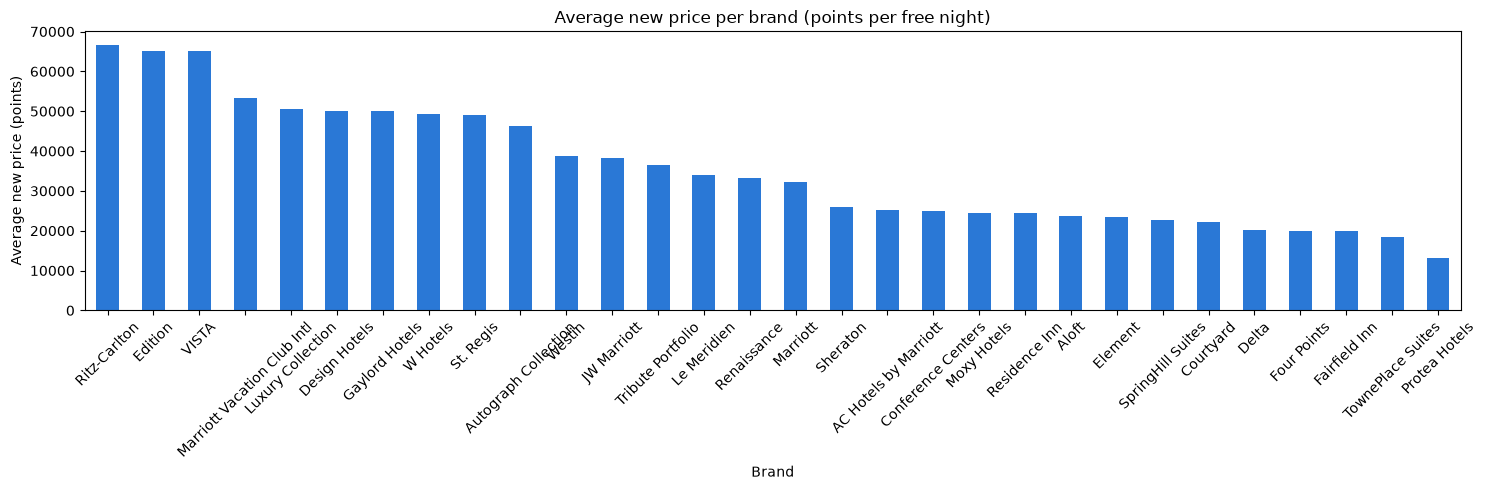

brand
Ritz-Carlton    66724.137931
Edition         65000.000000
VISTA           65000.000000
Name: new_price, dtype: float64

In [4]:
avg_price = df.groupby("brand")["new_price"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(15, 5))
avg_price.plot(kind="bar", ax=ax, color=BLUE)
ax.set_title("Average new price per brand (points per free night)")
ax.set_xlabel("Brand")
ax.set_ylabel("Average new price (points)")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

avg_price.head(3)

## 3. Average new price per brand

The three most expensive brands by average new price are:

1. **Ritz-Carlton** — 66,724 points per night
2. **Edition** — 65,000 points per night
3. **VISTA** — 65,000 points per night

These sit far above the mid-tier (Marriott ≈ 32,000; Sheraton ≈ 26,000) and the budget end (Protea Hotels ≈ 13,200), so the premium and luxury brands are in a different price band entirely.

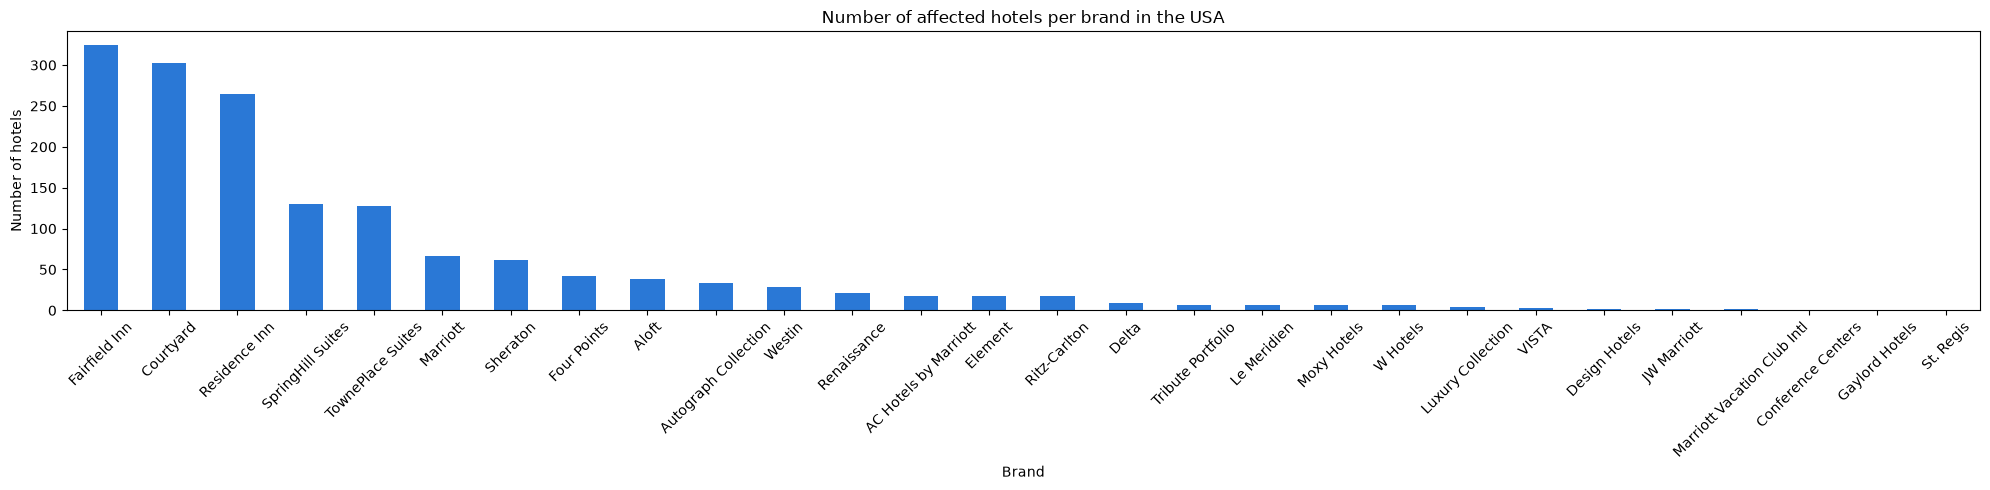

brand
Fairfield Inn        325
Courtyard            303
Residence Inn        265
SpringHill Suites    130
TownePlace Suites    128
Name: count, dtype: int64

In [5]:
usa = df[df["destination"] == "USA"]
usa_counts = usa["brand"].value_counts()

fig, ax = plt.subplots(figsize=(20, 5))
usa_counts.plot(kind="bar", ax=ax, color=BLUE)
ax.set_title("Number of affected hotels per brand in the USA")
ax.set_xlabel("Brand")
ax.set_ylabel("Number of hotels")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

usa_counts.head(5)

## 4. Affected hotels per brand in the USA

The USA dominates the dataset with 1,545 of the 2,182 hotels. Within the USA, the select-service brands account for most of the changes:

- **Fairfield Inn** — 325 hotels (the most)
- **Courtyard** — 303
- **Residence Inn** — 265
- **SpringHill Suites** — 130
- **TownePlace Suites** — 128

Those five brands alone are about 1,151 of the 1,545 USA hotels (≈ 74%), which reflects how large a share of Marriott's US footprint they make up.

In [6]:
upgraded = df[df["new_category"] > df["current_category"]]
n_upgraded = len(upgraded)

WORLDWIDE_TOTAL = 7737  # stated in the case description, not in the dataset

print("Hotels upgraded (category increased):", n_upgraded)
print("Share of the 2,182 hotels in this file:", round(n_upgraded / len(df) * 100, 2), "%")
print("Share of Marriott's 7,737 worldwide hotels:", round(n_upgraded / WORLDWIDE_TOTAL * 100, 2), "%")

Hotels upgraded (category increased): 1683
Share of the 2,182 hotels in this file: 77.13 %
Share of Marriott's 7,737 worldwide hotels: 21.75 %


## 5. Share of worldwide hotels upgraded

**1,683** hotels were upgraded, which is **21.75%** of Marriott's **7,737** worldwide hotels.

**Why the distinction matters:** this file contains *only* the hotels whose category changed, so its 2,182 rows are a subset of the network, not the network. Dividing by 2,182 would give 77%, which is the share of *changed* hotels that happened to be upgrades — not the share of *all* Marriott hotels. The worldwide percentage needs the 7,737 denominator, and that number has to come from the case description because it is not in the data.

In [7]:
# (a) hotels that moved by more than one category
moved = df[(df["new_category"] - df["current_category"]).abs() > 1]
moved[["hotel", "brand", "destination", "current_category", "new_category"]]

,hotel,brand,destination,current_category,new_category
911,"Four Points by Sheraton Bali, Ungasan",Four Points,Indonesia,4,2


In [8]:
# (b) JW Marriott hotels in China that were upgraded
jw_china_up = df[
    (df["brand"] == "JW Marriott")
    & (df["destination"] == "China")
    & (df["new_category"] > df["current_category"])
]
jw_china_up[["hotel", "current_category", "new_category", "new_price"]]

,hotel,current_category,new_category,new_price
1072,JW Marriott Hotel Chengdu,3,4,25000
1076,JW Marriott Hotel Shenzhen,3,4,25000
1077,JW Marriott Hotel Shenzhen Bao'an,3,4,25000
1081,JW Marriott Hotel Zhengzhou,2,3,17500


## 6. Large moves and JW Marriott in China

**(a) Hotels that moved by more than one category** — exactly one:

- **Four Points by Sheraton Bali, Ungasan** (Indonesia): 4 → 2, i.e. down two categories.

**(b) JW Marriott hotels in China that were upgraded** — four:

- JW Marriott Hotel Chengdu — 3 → 4
- JW Marriott Hotel Shenzhen — 3 → 4
- JW Marriott Hotel Shenzhen Bao'an — 3 → 4
- JW Marriott Hotel Zhengzhou — 2 → 3

In [9]:
cities = df[
    (df["hotel"].str.contains("Florence", case=False) & (df["destination"] == "Italy"))
    | (df["hotel"].str.contains("Hong Kong", case=False))
]
cities[["hotel", "brand", "destination", "current_category", "current_price", "new_category", "new_price"]]

,hotel,brand,destination,current_category,current_price,new_category,new_price
285,Courtyard Hong Kong Sha Tin,Courtyard,Hong Kong,2,12500,3,17500
1965,"The Westin Excelsior, Florence",Westin,Italy,7,60000,8,85000
2162,W Hong Kong,W Hotels,China,8,85000,7,60000


## 7. Booking advice — Florence and Hong Kong

You only stay in **category 8** hotels, or in a **category 7 hotel that was downgraded from 8**. The changes take effect 4 March; you travel in April. Since the data only contains hotels that changed, the relevant options are:

**Florence, Italy → book *The Westin Excelsior, Florence* (Westin).**

- It is the only Florence property in the data, and it is being **upgraded from category 7 (60,000 points) to category 8 (85,000 points)**.
- It satisfies your category-8 rule once the change takes effect.
- **Book BEFORE 4 March.** At that point it is still priced as a category 7 (60,000 points), so you lock in the lower rate before the upgrade pushes it to 85,000. Booking after 4 March costs 25,000 points more a night.

**Hong Kong, China → book *W Hong Kong* (W Hotels).**

- It is currently **category 8 (85,000 points)** and is being **downgraded to category 7 (60,000 points)**.
- It qualifies under your rule either way — now as a category 8, and after 4 March as a category 7 downgraded from 8.
- **Book AFTER 4 March.** The downgrade drops the price from 85,000 to 60,000 points, so waiting saves 25,000 points a night; booking before would leave you paying the old category-8 rate.

Both bookings end up at **60,000 points per night** — the cheapest rate at a hotel you would actually stay in — but the timing is opposite, because one hotel is going *up* and the other is going *down*.